ORIGINAL DATASET
Shape: (541909, 8)

First five rows:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom



BEFORE CLEANING


,Column,Data_Type,Missing_Values,Missing_Percentage,Unique_Values
0,InvoiceNo,object,0,0.00,25900
1,StockCode,object,0,0.00,4070
2,Description,object,1454,0.27,4223
3,Quantity,int64,0,0.00,722
4,InvoiceDate,datetime64[ns],0,0.00,23260
5,UnitPrice,float64,0,0.00,1630
6,CustomerID,float64,135080,24.93,4372
7,Country,object,0,0.00,38



AFTER CLEANING


,Column,Data_Type,Missing_Values,Missing_Percentage,Unique_Values
0,InvoiceNo,object,0,0.00,23796
1,StockCode,string,0,0.00,3938
2,Description,string,0,0.00,4031
3,Quantity,int64,0,0.00,510
4,InvoiceDate,datetime64[ns],0,0.00,21802
5,UnitPrice,float64,0,0.00,1628
6,CustomerID,float64,132565,24.82,4371
7,Country,string,0,0.00,38
8,Is_Return,bool,0,0.00,2
9,Invalid_UnitPrice,bool,0,0.00,1



CLEANING SUMMARY


,Metric,Before,After
0,Number of rows,541909,534129
1,Number of columns,8,14
2,Duplicate rows,5268,0
3,Missing cells,136534,132565


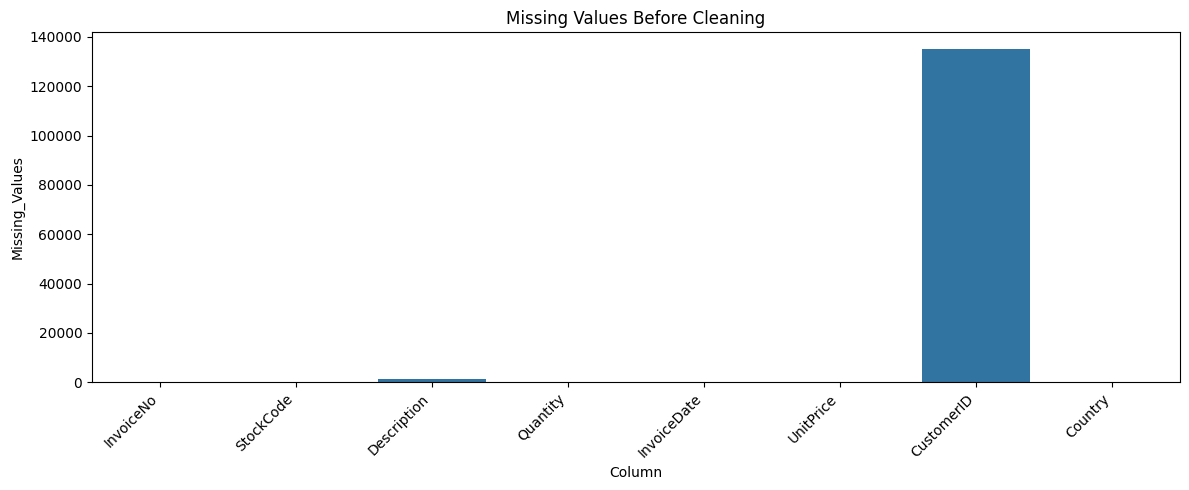

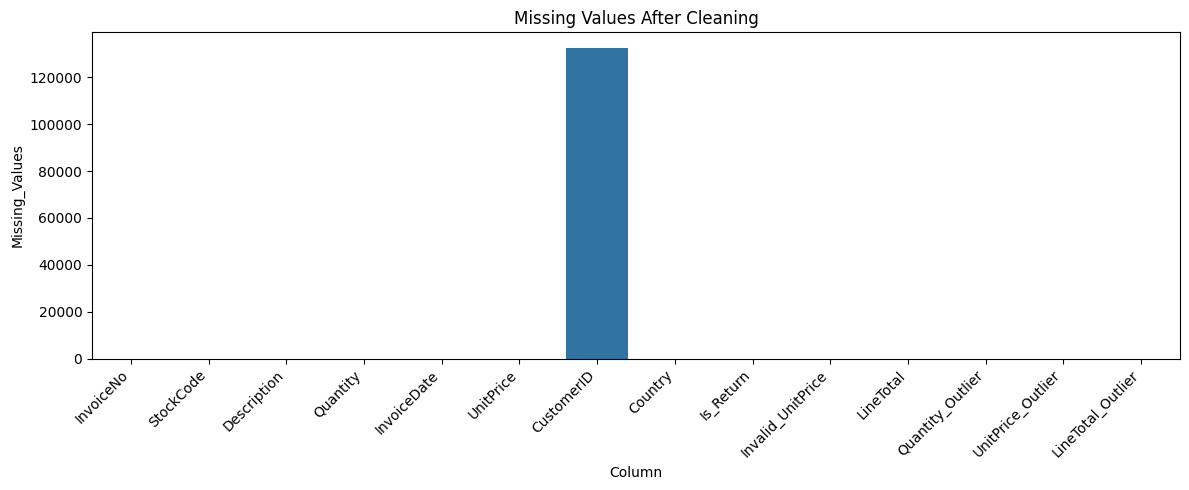

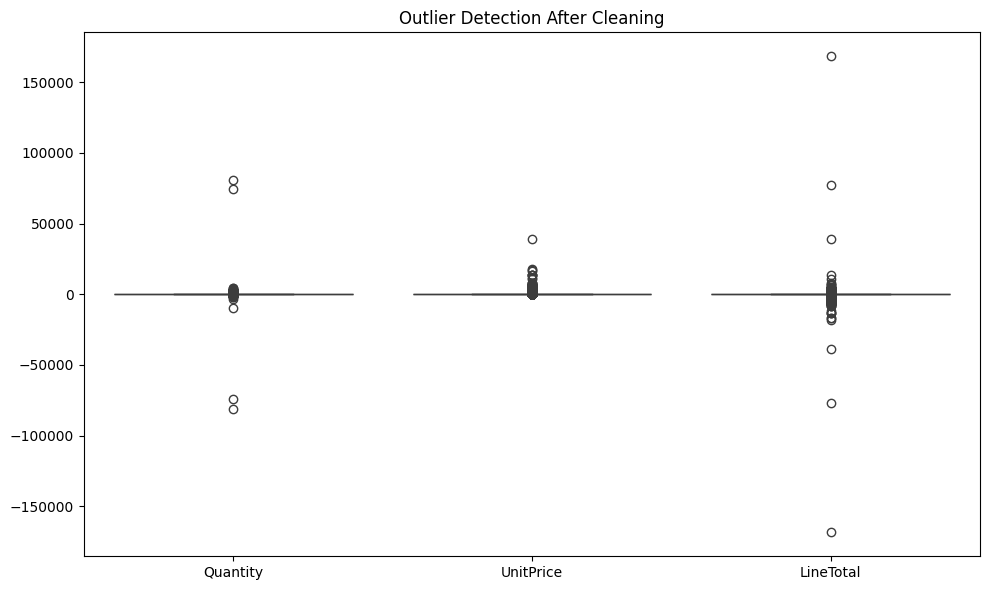

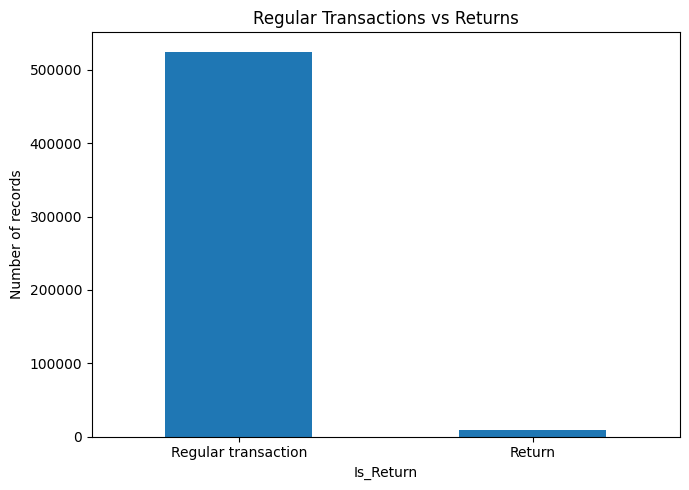


PROJECT COMPLETED
Original rows: 541909
Cleaned rows: 534129
Cleaned columns: 14
Files saved successfully.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [2]:

# ============================================================
# OASIS INFOBYTE - DATA ANALYTICS LEVEL 1 TASK 3
# DATA CLEANING AND QUALITY ASSESSMENT
# ============================================================

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

# 1. CREATE OUTPUT FOLDER
os.makedirs("outputs", exist_ok=True)

# 2. LOAD DATASET
file_path = "/content/Online Retail.xlsx"
df = pd.read_excel(file_path)

print("ORIGINAL DATASET")
print("Shape:", df.shape)
print("\nFirst five rows:")
display(df.head())

# 3. STANDARDISE COLUMN NAMES
df.columns = (
    df.columns.astype(str)
    .str.strip()
    .str.replace(" ", "_")
    .str.replace(r"[^A-Za-z0-9_]", "", regex=True)
)

# 4. CREATE INITIAL DATA QUALITY REPORT
def quality_report(data):
    return pd.DataFrame({
        "Column": data.columns,
        "Data_Type": [str(data[col].dtype) for col in data.columns],
        "Missing_Values": [data[col].isna().sum() for col in data.columns],
        "Missing_Percentage": [
            round(data[col].isna().mean() * 100, 2)
            for col in data.columns
        ],
        "Unique_Values": [data[col].nunique(dropna=True) for col in data.columns]
    })

before_report = quality_report(df)
print("\nBEFORE CLEANING")
display(before_report)

before_duplicates = df.duplicated().sum()

# 5. STANDARDISE TEXT FIELDS
for col in ["Description", "Country"]:
    if col in df.columns:
        df[col] = df[col].astype("string").str.strip()

if "StockCode" in df.columns:
    df["StockCode"] = df["StockCode"].astype("string").str.strip()

# 6. CORRECT DATA TYPES
df["InvoiceDate"] = pd.to_datetime(
    df["InvoiceDate"], errors="coerce"
)

for col in ["Quantity", "UnitPrice"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# 7. REMOVE DUPLICATE RECORDS
df = df.drop_duplicates().copy()

# 8. HANDLE MISSING VALUES
# Remove records missing essential transaction information.
essential_columns = [
    "InvoiceNo", "InvoiceDate", "StockCode",
    "Quantity", "UnitPrice"
]

df = df.dropna(subset=essential_columns).copy()

# Description is useful but not essential to calculate sales.
df["Description"] = df["Description"].fillna("Unknown")

# CustomerID is an identifier, so do not invent customer IDs.
# Preserve missing CustomerID values and report them.

# 9. IDENTIFY INVALID VALUES
# Keep negative quantities because they can represent legitimate returns.
# Flag them rather than automatically deleting them.
df["Is_Return"] = df["Quantity"] < 0

# Flag zero or negative unit prices for investigation.
df["Invalid_UnitPrice"] = df["UnitPrice"] <= 0

# Remove records with invalid/non-positive unit prices.
df = df[df["UnitPrice"] > 0].copy()

# 10. CREATE TRANSACTION VALUE
df["LineTotal"] = df["Quantity"] * df["UnitPrice"]

# 11. OUTLIER DETECTION USING IQR
def iqr_limits(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

for col in ["Quantity", "UnitPrice", "LineTotal"]:
    lower, upper = iqr_limits(df[col])
    df[f"{col}_Outlier"] = (
        (df[col] < lower) | (df[col] > upper)
    )

# Outliers are flagged, not automatically deleted.
# This prevents legitimate large transactions and returns
# from being removed without investigation.

# 12. FINAL DATA QUALITY REPORT
after_report = quality_report(df)

print("\nAFTER CLEANING")
display(after_report)

# 13. BEFORE-AND-AFTER SUMMARY
summary = pd.DataFrame({
    "Metric": [
        "Number of rows",
        "Number of columns",
        "Duplicate rows",
        "Missing cells"
    ],
    "Before": [
        len(pd.read_excel(file_path)),
        len(pd.read_excel(file_path).columns),
        before_duplicates,
        int(before_report["Missing_Values"].sum())
    ],
    "After": [
        len(df),
        len(df.columns),
        int(df.duplicated().sum()),
        int(df.isna().sum().sum())
    ]
})

print("\nCLEANING SUMMARY")
display(summary)

# 14. VISUALISE MISSING VALUES BEFORE CLEANING
plt.figure(figsize=(12, 5))
sns.barplot(
    data=before_report,
    x="Column",
    y="Missing_Values"
)
plt.title("Missing Values Before Cleaning")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("outputs/missing_values_before.png", dpi=300)
plt.show()

# 15. VISUALISE MISSING VALUES AFTER CLEANING
plt.figure(figsize=(12, 5))
sns.barplot(
    data=after_report,
    x="Column",
    y="Missing_Values"
)
plt.title("Missing Values After Cleaning")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("outputs/missing_values_after.png", dpi=300)
plt.show()

# 16. VISUALISE OUTLIERS
plt.figure(figsize=(10, 6))
sns.boxplot(data=df[["Quantity", "UnitPrice", "LineTotal"]])
plt.title("Outlier Detection After Cleaning")
plt.tight_layout()
plt.savefig("outputs/outlier_detection.png", dpi=300)
plt.show()

# 17. VISUALISE RETURN RECORDS
return_counts = df["Is_Return"].value_counts().rename(
    index={False: "Regular transaction", True: "Return"}
)

plt.figure(figsize=(7, 5))
return_counts.plot(kind="bar")
plt.title("Regular Transactions vs Returns")
plt.ylabel("Number of records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("outputs/returns_analysis.png", dpi=300)
plt.show()

# 18. EXPORT CLEANED DATA AND REPORTS
df.to_csv("cleaned_online_retail.csv", index=False)

before_report.to_csv(
    "outputs/data_quality_before.csv", index=False
)

after_report.to_csv(
    "outputs/data_quality_after.csv", index=False
)

summary.to_csv(
    "outputs/cleaning_summary.csv", index=False
)

print("\nPROJECT COMPLETED")
print("Original rows:", len(pd.read_excel(file_path)))
print("Cleaned rows:", len(df))
print("Cleaned columns:", len(df.columns))
print("Files saved successfully.")

# 19. DOWNLOAD CLEANED DATASET
files.download("cleaned_online_retail.csv")
